# tinyrl

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy

In [26]:
RUNS_CSV_FILE = "./mujoco_runs.csv"

AVG_FILTER_SIZE = 50
ALPHA_MEAN = 0.8
ALPHA_STD = 0.2

ENV_ORDER = [
    "Pusher",
    "Hopper",
    "Walker2d",
    "HalfCheetah",
    "Humanoid",
    "Ant",
]

ALG_COLORS = {
    "ddpg": "blue", 
    "td3": "green", 
    "sac": "red"
}

ALG_NAMES = {
    "ddpg": "DDPG", 
    "td3": "TD3",
    "sac": "SAC"
}

In [27]:
df_runs = pd.read_csv(RUNS_CSV_FILE)
df_runs.head()

,algorithm,env,step,mean_return,std_return
0,ddpg,ant,0,87.201701,18.488094
1,ddpg,ant,1,12.499766,22.633997
2,ddpg,ant,2,45.425392,30.820694
3,ddpg,ant,3,30.186244,9.739754
4,ddpg,ant,4,193.382357,43.575501


In [28]:
print(df_runs.shape)

(2400, 5)


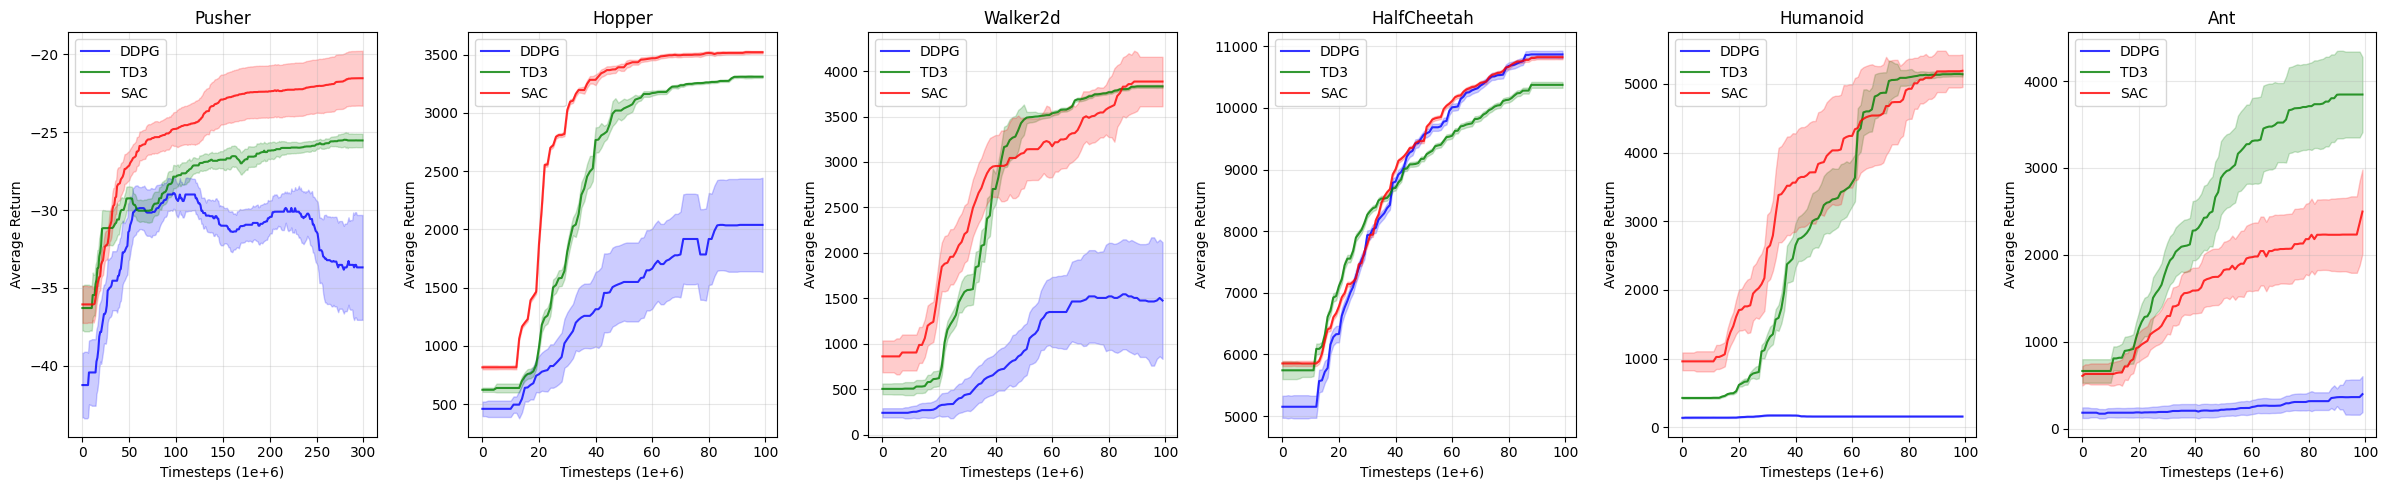

In [29]:
fig, ax = plt.subplots(nrows=1, ncols=6, figsize=(24, 5))
ax = ax.flatten()

for alg in ALG_NAMES.keys():
    df_alg = df_runs[df_runs["algorithm"] == alg]
    
    for i, env_name in enumerate(ENV_ORDER):
        df_env = df_alg[df_alg["env"] == env_name.lower()]
        
        timesteps = df_env["step"]
        mean = scipy.ndimage.median_filter(
            df_env["mean_return"],
            size=AVG_FILTER_SIZE,
         )
        std = scipy.ndimage.median_filter(
            df_env["std_return"].fillna(0.0),
            size=AVG_FILTER_SIZE,
        )

        lower = mean - std
        upper = mean + std

        ax[i].plot(
            timesteps,
            mean,
            label=ALG_NAMES[alg],
            color=ALG_COLORS[alg],
            alpha=ALPHA_MEAN,
        )

        ax[i].fill_between(
            timesteps,
            lower,
            upper,
            color=ALG_COLORS[alg],
            alpha=ALPHA_STD,
        )

        ax[i].set_title(env_name)
        ax[i].set_xlabel("Timesteps (1e+6)")
        ax[i].set_ylabel("Average Return")
        ax[i].grid(alpha=0.3)
        ax[i].legend()

plt.tight_layout()
plt.show()

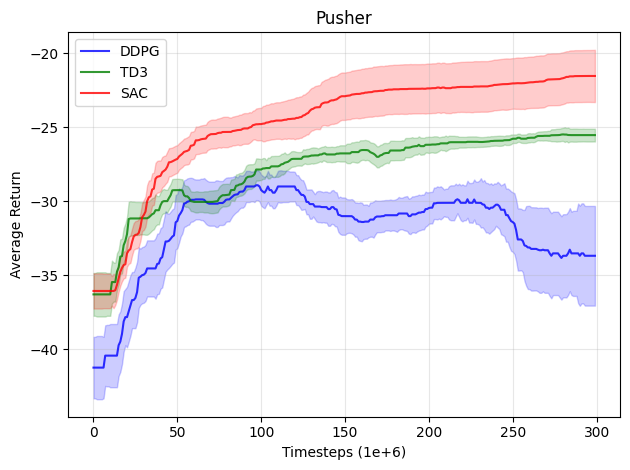

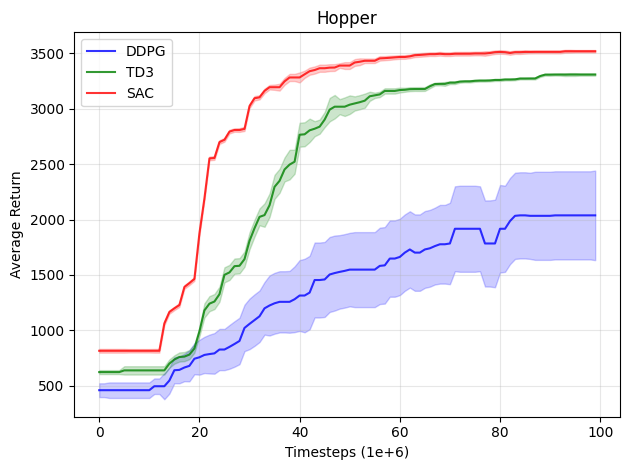

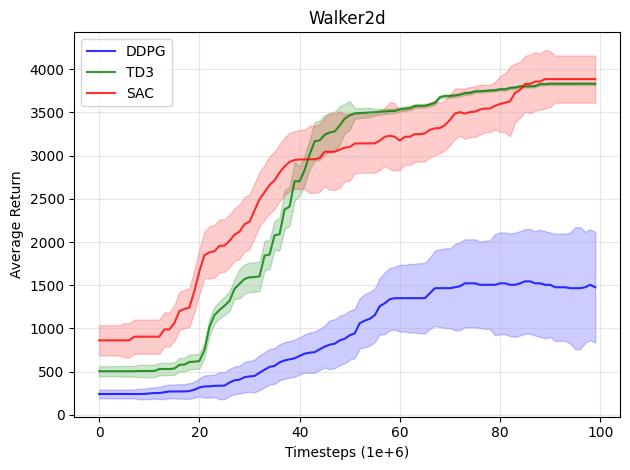

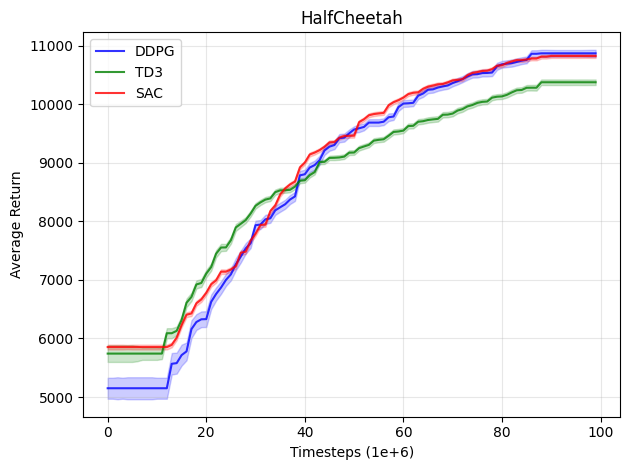

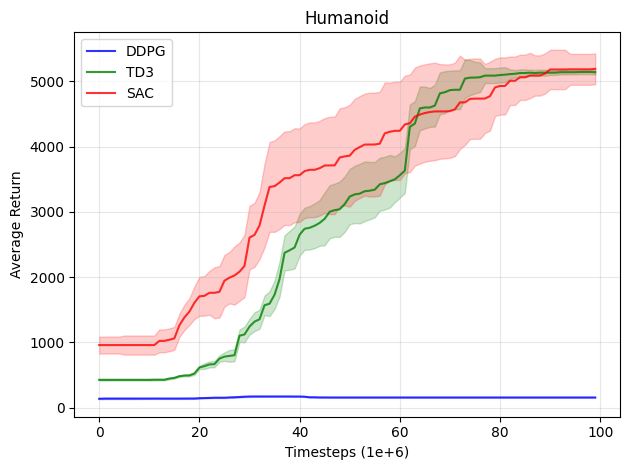

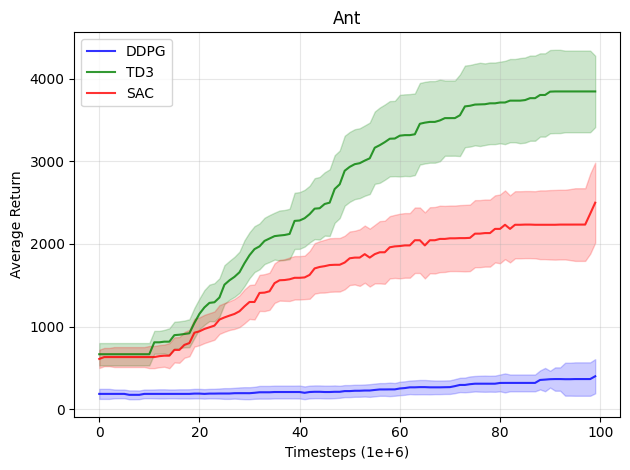

In [30]:
for i, env_name in enumerate(ENV_ORDER):
    fig, ax = plt.subplots()
    df_env = df_runs[df_runs["env"] == env_name.lower()]
    
    for alg in ALG_NAMES.keys():
        df_alg = df_env[df_env["algorithm"] == alg.lower()]
        
        timesteps = df_alg["step"]
        mean = scipy.ndimage.median_filter(
            df_alg["mean_return"],
            size=AVG_FILTER_SIZE,
         )
        std = scipy.ndimage.median_filter(
            df_alg["std_return"].fillna(0.0),
            size=AVG_FILTER_SIZE,
        )

        lower = mean - std
        upper = mean + std

        ax.plot(
            timesteps,
            mean,
            label=ALG_NAMES[alg],
            color=ALG_COLORS[alg],
            alpha=ALPHA_MEAN,
        )

        ax.fill_between(
            timesteps,
            lower,
            upper,
            color=ALG_COLORS[alg],
            alpha=ALPHA_STD,
        )

        ax.set_title(env_name)
        ax.set_xlabel("Timesteps (1e+6)")
        ax.set_ylabel("Average Return")
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()